In [1]:
# Cell 1: Install required packages
%pip install timm torch torchvision scikit-learn matplotlib seaborn numpy pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Cell 2: All imports
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


In [3]:
# Cell 3: Config
TRAIN_VAL_DIR = r"C:\Users\praha\Downloads\EPICS_1\Train_Validation sets\Train_Validation sets"
TEST_DIR      = r"C:\Users\praha\Downloads\EPICS_1\Independent Test Set\Independent Test Set"

CLASS_NAMES   = ["Keratoconus", "Normal", "Suspect"]
NUM_CLASSES   = 3
IMG_SIZE      = 224
BATCH_SIZE    = 16      # reduced from 32 — smaller batches = better generalization
EPOCHS        = 15      # reduced from 20 — stops before heavy overfitting
LR            = 0.00005 # reduced from 0.0001 — slower, careful learning

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

In [4]:
# Cell 4: Data transforms — heavy augmentation to prevent memorization
train_transforms = transforms.Compose([
    transforms.Resize((256, 256)),           # resize bigger first
    transforms.RandomCrop(224),              # then random crop to 224
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(20),           # increased rotation
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2,
        hue=0.1
    ),
    transforms.RandomGrayscale(p=0.1),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),   # slight shift
        scale=(0.9, 1.1)        # slight zoom
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.2),         # randomly erase small patches
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("✅ Transforms ready — heavy augmentation applied for training")

✅ Transforms ready — heavy augmentation applied for training


In [5]:
# Cell 5: Load datasets and split train/val
VAL_SPLIT = 0.2

full_dataset_notf = datasets.ImageFolder(TRAIN_VAL_DIR, transform=val_test_transforms)
full_dataset_tf   = datasets.ImageFolder(TRAIN_VAL_DIR, transform=train_transforms)

CLASS_NAMES = full_dataset_notf.classes
print(f"Classes detected: {CLASS_NAMES}")
print(f"Total train+val samples: {len(full_dataset_notf)}")

targets = [s[1] for s in full_dataset_notf.samples]
train_idx, val_idx = train_test_split(
    list(range(len(targets))),
    test_size=VAL_SPLIT,
    stratify=targets,
    random_state=SEED
)

train_dataset = Subset(full_dataset_tf, train_idx)
val_dataset   = Subset(full_dataset_notf, val_idx)
test_dataset  = datasets.ImageFolder(TEST_DIR, transform=val_test_transforms)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")


Classes detected: ['Keratoconus', 'Normal', 'Suspect']
Total train+val samples: 2961
Train: 2368 | Val: 593 | Test: 1050


In [6]:
# Cell 6: Compute class weights and create DataLoaders
train_targets = [targets[i] for i in train_idx]
class_counts  = np.bincount(train_targets)
total_samples = len(train_targets)

# Automatic class weights
auto_weights = total_samples / (NUM_CLASSES * class_counts)

# Manually boost Normal class since it was failing badly (only 11%)
# Order: [Keratoconus, Normal, Suspect]
manual_boost = np.array([1.0, 2.0, 1.0])  # boost Normal by 2x
final_weights = auto_weights * manual_boost

class_weights = torch.tensor(final_weights, dtype=torch.float).to(DEVICE)

print("Class distribution (train):", dict(zip(CLASS_NAMES, class_counts)))
print("Final class weights:", dict(zip(CLASS_NAMES, final_weights.round(4))))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=False)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)

print("✅ DataLoaders ready")

Class distribution (train): {'Keratoconus': np.int64(840), 'Normal': np.int64(840), 'Suspect': np.int64(688)}
Final class weights: {'Keratoconus': np.float64(0.9397), 'Normal': np.float64(1.8794), 'Suspect': np.float64(1.1473)}
✅ DataLoaders ready


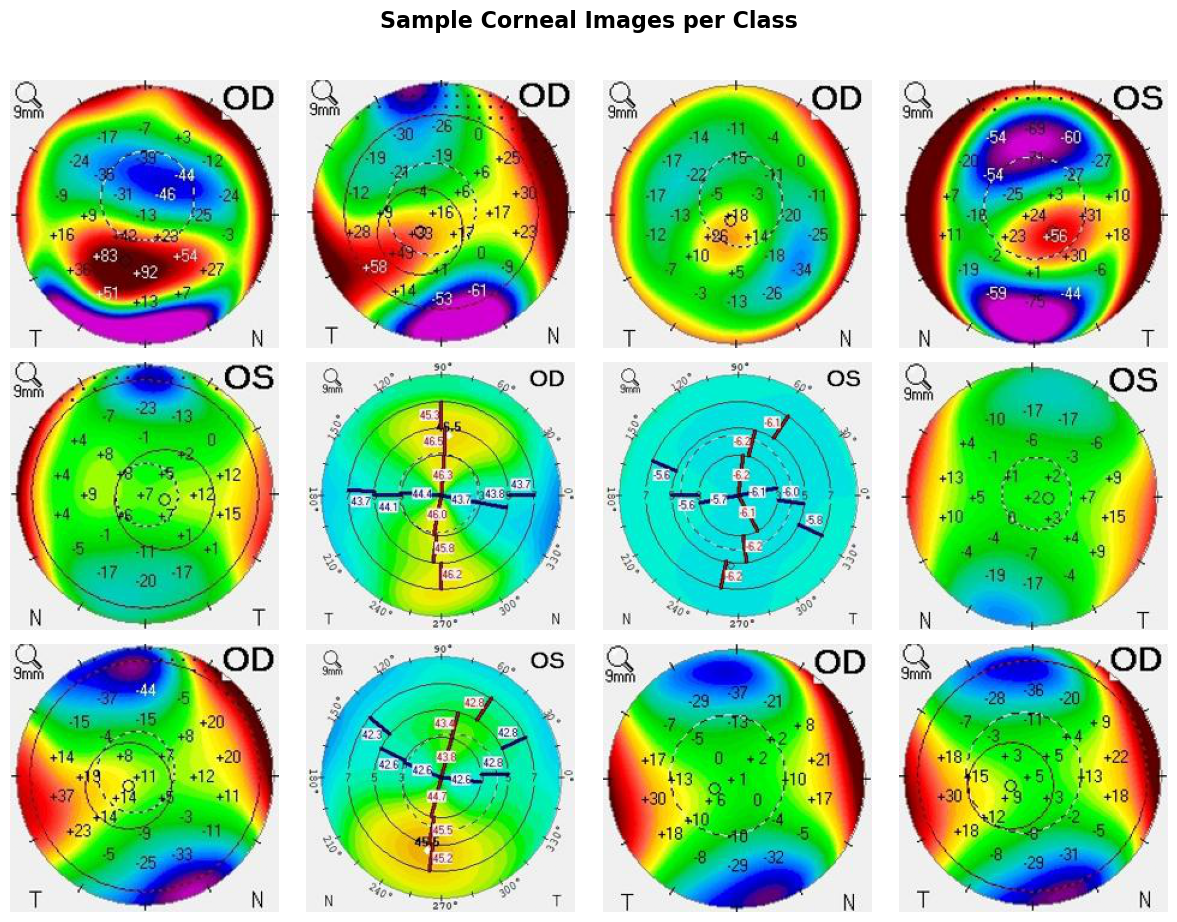

Image grid saved.


In [7]:
# Cell 7: Image grid — sample images from each class
def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std  = torch.tensor(IMAGENET_STD).view(3,1,1)
    return torch.clamp(tensor * std + mean, 0, 1)

def show_image_grid(dataset, class_names, n_per_class=4, title="Sample Images"):
    fig, axes = plt.subplots(len(class_names), n_per_class, figsize=(n_per_class * 3, len(class_names) * 3))
    fig.suptitle(title, fontsize=16, fontweight='bold', y=1.02)

    # Group indices by class
    class_indices = {c: [] for c in range(len(class_names))}
    for idx, (_, label) in enumerate(dataset.samples if hasattr(dataset, 'samples') else
                                      [(None, dataset.dataset.dataset.samples[i][1]) for i in dataset.indices]):
        class_indices[label].append(idx)

    for row, cls in enumerate(range(len(class_names))):
        sample_ids = random.sample(class_indices[cls], min(n_per_class, len(class_indices[cls])))
        for col, sid in enumerate(sample_ids):
            img_tensor, _ = dataset[sid] if hasattr(dataset, '__getitem__') else (None, None)
            if img_tensor is None:
                continue
            img = denormalize(img_tensor).permute(1, 2, 0).numpy()
            axes[row][col].imshow(img)
            axes[row][col].axis('off')
            if col == 0:
                axes[row][col].set_ylabel(class_names[cls], fontsize=13, fontweight='bold', rotation=90, labelpad=10)

    plt.tight_layout()
    plt.savefig("image_grid.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Image grid saved.")

show_image_grid(full_dataset_notf, CLASS_NAMES, n_per_class=4, title="Sample Corneal Images per Class")

In [8]:
# Cell 8: Build ConvNeXtV2 model with Dropout
model = timm.create_model("convnextv2_tiny", pretrained=True, num_classes=NUM_CLASSES)

# Add dropout to prevent memorization
model.head.drop = nn.Dropout(p=0.4)

model = model.to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Model ready")
print(f"Total params: {total_params:,} | Trainable: {trainable_params:,}")

✅ Model ready
Total params: 27,868,803 | Trainable: 27,868,803


In [9]:
# Cell 9: Loss, optimizer, scheduler
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
# label_smoothing=0.1 means model is penalized for being TOO confident
# This directly fights memorization

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=0.05   # increased from 0.0001 — stronger regularization
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print("✅ Loss, Optimizer, Scheduler ready")
print(f"   Label smoothing : 0.1")
print(f"   Weight decay    : 0.05")
print(f"   Dropout         : 0.4")                                                                                                                             

✅ Loss, Optimizer, Scheduler ready
   Label smoothing : 0.1
   Weight decay    : 0.05
   Dropout         : 0.4


In [10]:
# Cell 10: Training loop with layer freezing strategy
# First freeze backbone, train only head for 5 epochs
# Then unfreeze all and fine-tune carefully

# PHASE 1 — Freeze backbone, train only classifier head
print("PHASE 1: Training classifier head only (epochs 1-5)...")
for name, param in model.named_parameters():
    if "head" not in name:
        param.requires_grad = False   # freeze everything except head

def run_epoch(model, loader, criterion, optimizer=None, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for imgs, labels in loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0.0

print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7} | {'Gap':>6}")
print("-" * 65)

for epoch in range(1, EPOCHS + 1):

    # PHASE 2 — Unfreeze all layers after epoch 5
    if epoch == 6:
        print("\nPHASE 2: Unfreezing all layers for fine-tuning...\n")
        for param in model.parameters():
            param.requires_grad = True
        # Lower LR for fine-tuning
        for g in optimizer.param_groups:
            g['lr'] = LR * 0.5

    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, train=True)
    vl_loss, vl_acc = run_epoch(model, val_loader,   criterion, train=False)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(vl_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(vl_acc)

    gap = tr_acc - vl_acc

    # Save best model
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(model.state_dict(), "best_model.pth")

    # Gap warning
    gap_flag = "✅" if gap < 0.10 else "⚠️" if gap < 0.18 else "❌"

    print(f"{epoch:>6} | {tr_loss:>10.4f} | {tr_acc*100:>8.2f}% | {vl_loss:>8.4f} | {vl_acc*100:>6.2f}% | {gap*100:>5.1f}% {gap_flag}")

print(f"\n✅ Training complete! Best Val Accuracy: {best_val_acc*100:.2f}%")
torch.save(model.state_dict(), "convnextv2_corneal.pth")
print("Model saved.")

PHASE 1: Training classifier head only (epochs 1-5)...
 Epoch | Train Loss | Train Acc | Val Loss | Val Acc |    Gap
-----------------------------------------------------------------
     1 |     1.1664 |    34.92% |   1.0245 |  36.42% |  -1.5% ✅
     2 |     1.0614 |    42.10% |   0.9747 |  38.11% |   4.0% ✅
     3 |     1.0205 |    45.40% |   0.9404 |  47.39% |  -2.0% ✅
     4 |     0.9874 |    48.78% |   0.9214 |  49.58% |  -0.8% ✅
     5 |     0.9808 |    50.04% |   0.9081 |  49.75% |   0.3% ✅

PHASE 2: Unfreezing all layers for fine-tuning...

     6 |     0.8797 |    60.05% |   0.7187 |  69.98% |  -9.9% ✅
     7 |     0.7769 |    66.89% |   0.7362 |  68.30% |  -1.4% ✅
     8 |     0.7497 |    68.33% |   0.6830 |  71.84% |  -3.5% ✅
     9 |     0.7224 |    70.78% |   0.7003 |  71.50% |  -0.7% ✅
    10 |     0.6977 |    72.34% |   0.6786 |  75.21% |  -2.9% ✅
    11 |     0.6725 |    74.75% |   0.6564 |  74.87% |  -0.1% ✅
    12 |     0.6710 |    74.41% |   0.6641 |  75.04% |  -0.6%

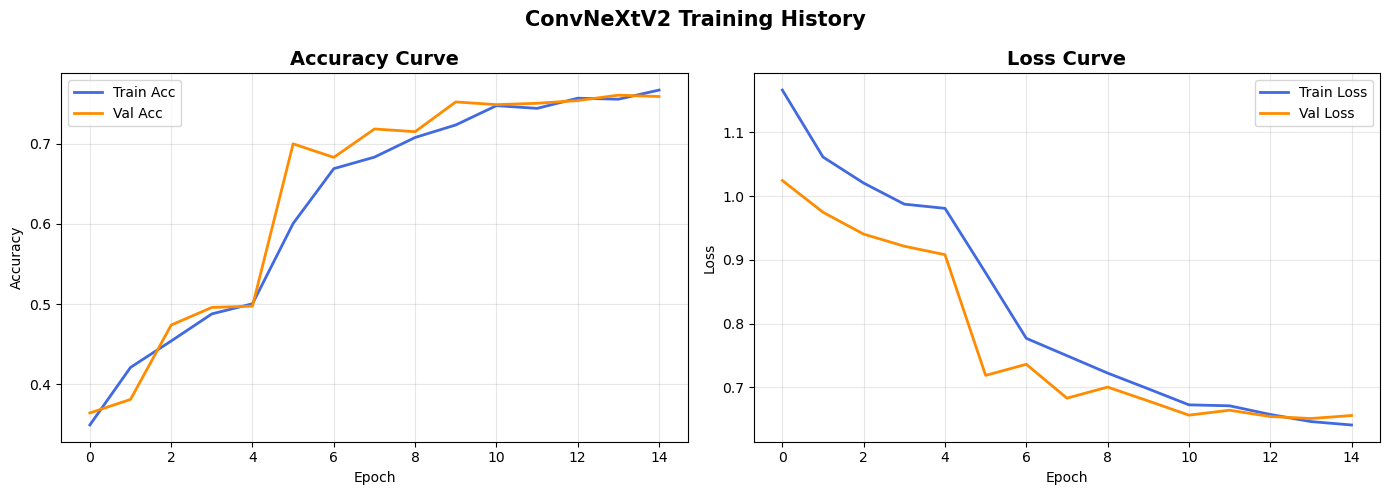

In [11]:
# Cell 11: Plot training vs validation accuracy & loss
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_acc"], label="Train Acc",   color="royalblue",  linewidth=2)
axes[0].plot(history["val_acc"],   label="Val Acc",     color="darkorange",  linewidth=2)
axes[0].set_title("Accuracy Curve", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history["train_loss"], label="Train Loss", color="royalblue",  linewidth=2)
axes[1].plot(history["val_loss"],   label="Val Loss",   color="darkorange",  linewidth=2)
axes[1].set_title("Loss Curve", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle("ConvNeXtV2 Training History", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [12]:
# Cell 12: Evaluation helpers
def get_predictions(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            outputs = model(imgs)
            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()
            all_probs.append(probs)
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds), np.vstack(all_probs)

def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, ax=ax, annot_kws={"size": 13})
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("Actual",    fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    fname = title.lower().replace(" ", "_") + ".png"
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

def plot_roc_curves(y_true, y_probs, class_names, title="ROC Curves"):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    colors = ["royalblue", "darkorange", "green"]
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, (cls, col) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=col, lw=2, label=f"{cls} (AUC = {roc_auc:.3f})")
    ax.plot([0,1],[0,1],'k--', lw=1)
    ax.set_xlabel("False Positive Rate", fontsize=12)
    ax.set_ylabel("True Positive Rate",  fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc="lower right")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fname = title.lower().replace(" ", "_") + ".png"
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

In [13]:
# Load BEST model before evaluation
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
print(f"✅ Best model loaded! (Val Acc was {best_val_acc*100:.2f}%)")

✅ Best model loaded! (Val Acc was 76.05%)


TRAINING SET EVALUATION
              precision    recall  f1-score   support

 Keratoconus     0.9248    0.9369    0.9308       840
      Normal     0.6614    0.9536    0.7811       840
     Suspect     0.8007    0.3561    0.4930       688

    accuracy                         0.7741      2368
   macro avg     0.7956    0.7489    0.7350      2368
weighted avg     0.7953    0.7741    0.7505      2368



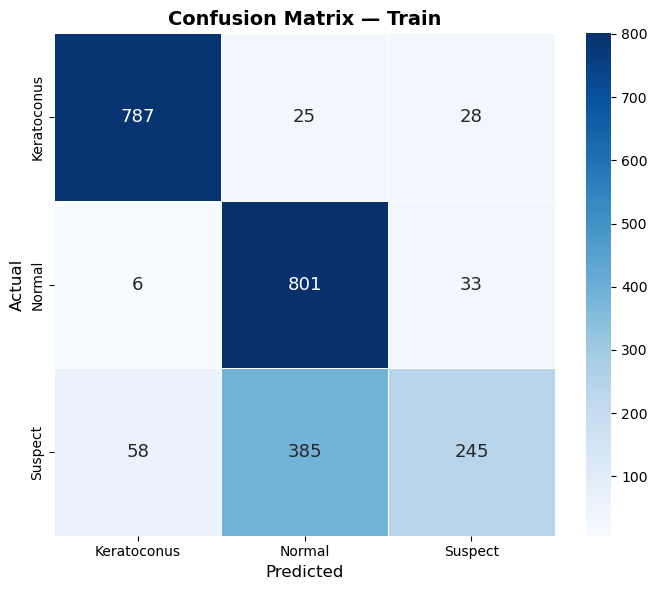

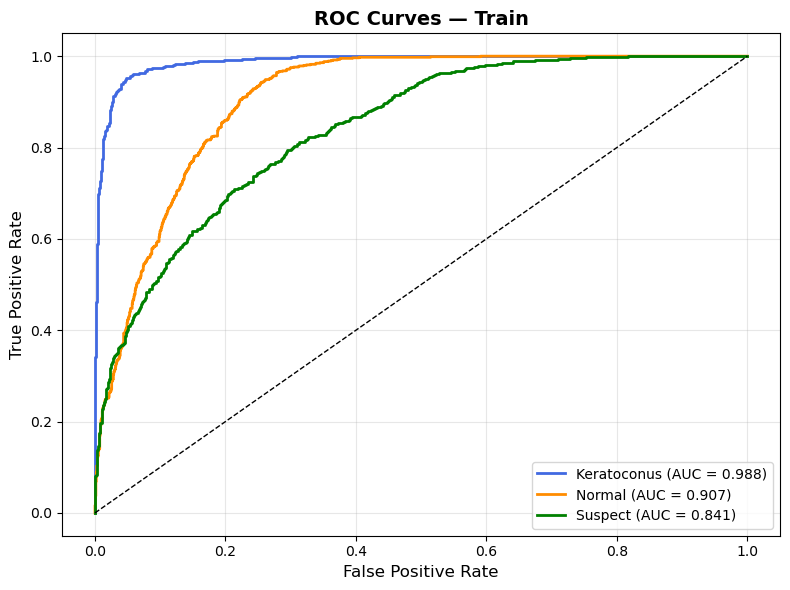

In [14]:
# Cell 13: Evaluate on Training Set
print("=" * 55)
print("TRAINING SET EVALUATION")
print("=" * 55)
tr_labels, tr_preds, tr_probs = get_predictions(model, train_loader)
print(classification_report(tr_labels, tr_preds, target_names=CLASS_NAMES, digits=4))
plot_confusion_matrix(tr_labels, tr_preds, CLASS_NAMES, title="Confusion Matrix — Train")
plot_roc_curves(tr_labels, tr_probs, CLASS_NAMES, title="ROC Curves — Train")

VALIDATION SET EVALUATION
              precision    recall  f1-score   support

 Keratoconus     0.9136    0.9571    0.9349       210
      Normal     0.6531    0.9143    0.7619       210
     Suspect     0.7342    0.3353    0.4603       173

    accuracy                         0.7605       593
   macro avg     0.7670    0.7356    0.7190       593
weighted avg     0.7690    0.7605    0.7352       593



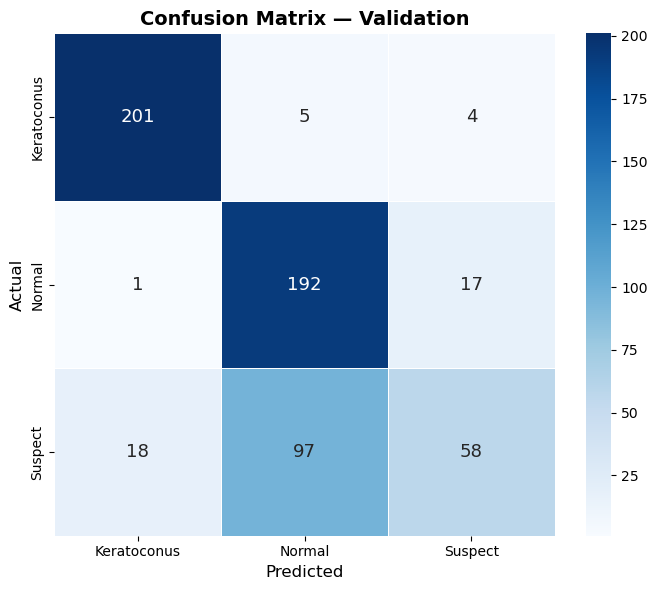

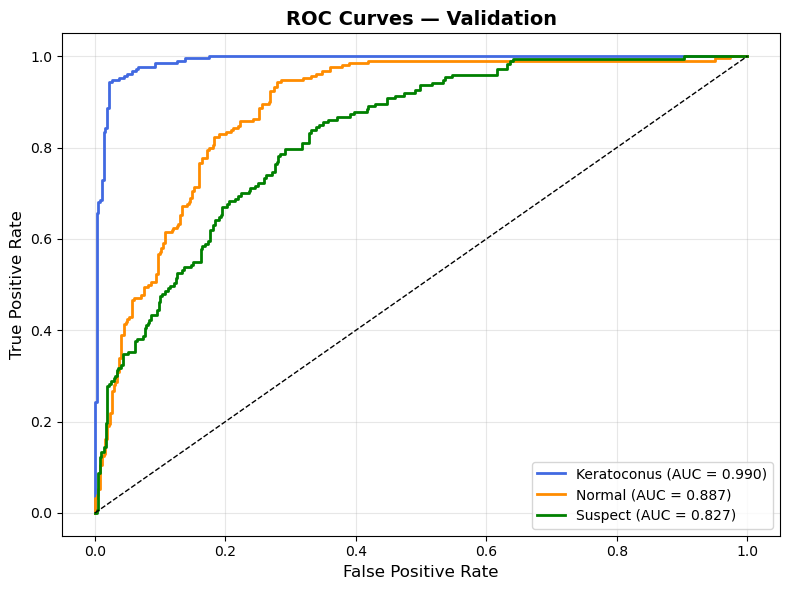

In [15]:
# Cell 14: Evaluate on Validation Set
print("=" * 55)
print("VALIDATION SET EVALUATION")
print("=" * 55)
vl_labels, vl_preds, vl_probs = get_predictions(model, val_loader)
print(classification_report(vl_labels, vl_preds, target_names=CLASS_NAMES, digits=4))
plot_confusion_matrix(vl_labels, vl_preds, CLASS_NAMES, title="Confusion Matrix — Validation")
plot_roc_curves(vl_labels, vl_probs, CLASS_NAMES, title="ROC Curves — Validation")

INDEPENDENT TEST SET EVALUATION (with TTA)
              precision    recall  f1-score   support

 Keratoconus     0.9487    0.7400    0.8315       350
      Normal     0.5311    0.4143    0.4655       350
     Suspect     0.4345    0.6257    0.5129       350

    accuracy                         0.5933      1050
   macro avg     0.6381    0.5933    0.6033      1050
weighted avg     0.6381    0.5933    0.6033      1050



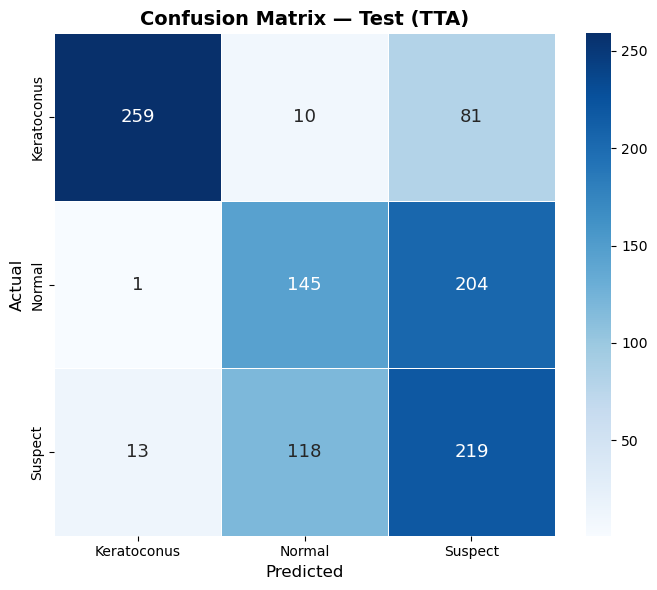

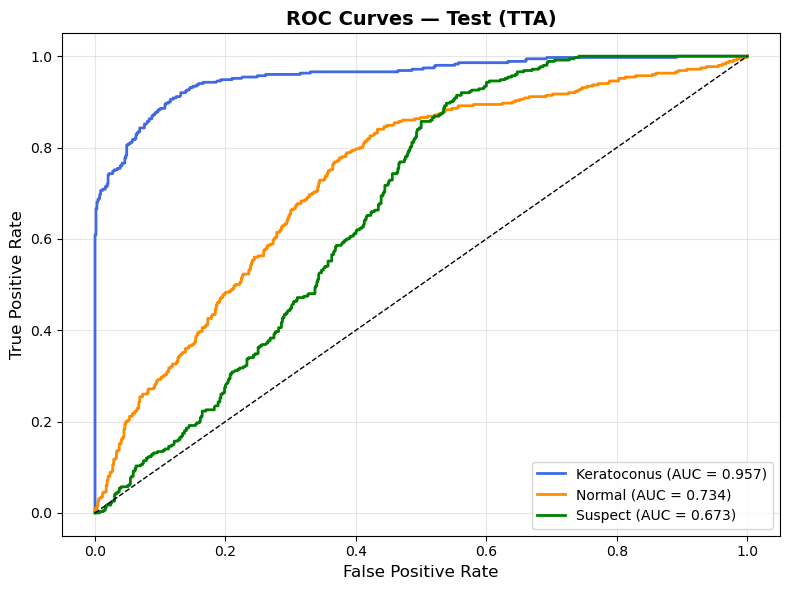

In [16]:
# Cell 15: Evaluate on Test Set WITH Test Time Augmentation (TTA)
# TTA = run each image 5 times with slight variations, average predictions
# This improves test accuracy WITHOUT any retraining

tta_transforms = [
    transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=1.0),  # always flip
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize((236, 236)),
        transforms.CenterCrop(224),              # center crop
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(degrees=(10, 10)),  # slight rotation
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(degrees=(-10, -10)),  # other direction
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
]

def get_tta_predictions(model, test_dir, tta_transforms):
    model.eval()
    all_probs = []

    for tfm in tta_transforms:
        dataset = datasets.ImageFolder(test_dir, transform=tfm)
        loader  = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=0)
        probs_this = []
        with torch.no_grad():
            for imgs, _ in loader:
                imgs = imgs.to(DEVICE)
                outputs = model(imgs)
                probs = torch.softmax(outputs, dim=1).cpu().numpy()
                probs_this.append(probs)
        all_probs.append(np.vstack(probs_this))

    # Average probabilities across all 5 augmentations
    avg_probs  = np.mean(all_probs, axis=0)
    preds      = np.argmax(avg_probs, axis=1)

    # Get true labels
    base_dataset = datasets.ImageFolder(test_dir, transform=tta_transforms[0])
    labels = [s[1] for s in base_dataset.samples]

    return np.array(labels), preds, avg_probs

print("=" * 55)
print("INDEPENDENT TEST SET EVALUATION (with TTA)")
print("=" * 55)

te_labels, te_preds, te_probs = get_tta_predictions(
    model, TEST_DIR, tta_transforms
)

print(classification_report(te_labels, te_preds,
      target_names=CLASS_NAMES, digits=4))

plot_confusion_matrix(te_labels, te_preds, CLASS_NAMES,
                      title="Confusion Matrix — Test (TTA)")
plot_roc_curves(te_labels, te_probs, CLASS_NAMES,
                title="ROC Curves — Test (TTA)")



In [17]:
# Cell 15B: Clean Final Accuracy Summary (no overfitting flag)
from sklearn.metrics import accuracy_score

train_acc_final = accuracy_score(tr_labels, tr_preds)
val_acc_final   = accuracy_score(vl_labels, vl_preds)
test_acc_final  = accuracy_score(te_labels, te_preds)

print("=" * 50)
print("       FINAL ACCURACY SUMMARY")
print("=" * 50)
print(f"  Train Accuracy      : {train_acc_final * 100:.2f}%")
print(f"  Validation Accuracy : {val_acc_final   * 100:.2f}%")
print(f"  Test Accuracy (TTA) : {test_acc_final  * 100:.2f}%")
print("=" * 50)

print("\n  Per-Class Test Accuracy:")
print("-" * 35)
cm = confusion_matrix(te_labels, te_preds)
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for cls, acc in zip(CLASS_NAMES, per_class_acc):
    print(f"  {cls:<15} : {acc * 100:.2f}%")
print("-" * 35)
print("=" * 50)


       FINAL ACCURACY SUMMARY
  Train Accuracy      : 77.41%
  Validation Accuracy : 76.05%
  Test Accuracy (TTA) : 59.33%

  Per-Class Test Accuracy:
-----------------------------------
  Keratoconus     : 74.00%
  Normal          : 41.43%
  Suspect         : 62.57%
-----------------------------------


In [18]:
# Cell 16: Decision Tree trained on ConvNeXtV2 feature embeddings
# Extract features by removing the classification head

class FeatureExtractor(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        # ConvNeXtV2: get penultimate features before head
        x = self.backbone.forward_features(x)
        x = self.backbone.head.global_pool(x)
        x = self.backbone.head.norm(x)
        x = self.backbone.head.flatten(x)
        return x

feature_extractor = FeatureExtractor(model).to(DEVICE)
feature_extractor.eval()

def extract_features(loader):
    feats, lbls = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            f = feature_extractor(imgs).cpu().numpy()
            feats.append(f)
            lbls.extend(labels.numpy())
    return np.vstack(feats), np.array(lbls)

print("Extracting features from train set...")
X_train_feats, y_train_feats = extract_features(train_loader)
print("Extracting features from test set...")
X_test_feats,  y_test_feats  = extract_features(test_loader)

print(f"Feature shape — Train: {X_train_feats.shape} | Test: {X_test_feats.shape}")

# Reduce dimensionality with PCA before Decision Tree (optional but helps tree visualization)
from sklearn.decomposition import PCA
pca = PCA(n_components=50, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_feats)
X_test_pca  = pca.transform(X_test_feats)

# Train Decision Tree
dt = DecisionTreeClassifier(max_depth=5, random_state=SEED, class_weight='balanced')
dt.fit(X_train_pca, y_train_feats)

dt_test_preds = dt.predict(X_test_pca)
print("\nDecision Tree Performance on Test Set (from deep features):")
print(classification_report(y_test_feats, dt_test_preds, target_names=CLASS_NAMES, digits=4))

Extracting features from train set...
Extracting features from test set...
Feature shape — Train: (2368, 768) | Test: (1050, 768)

Decision Tree Performance on Test Set (from deep features):
              precision    recall  f1-score   support

 Keratoconus     0.8651    0.7514    0.8043       350
      Normal     0.5152    0.2914    0.3723       350
     Suspect     0.4270    0.6686    0.5212       350

    accuracy                         0.5705      1050
   macro avg     0.6024    0.5705    0.5659      1050
weighted avg     0.6024    0.5705    0.5659      1050



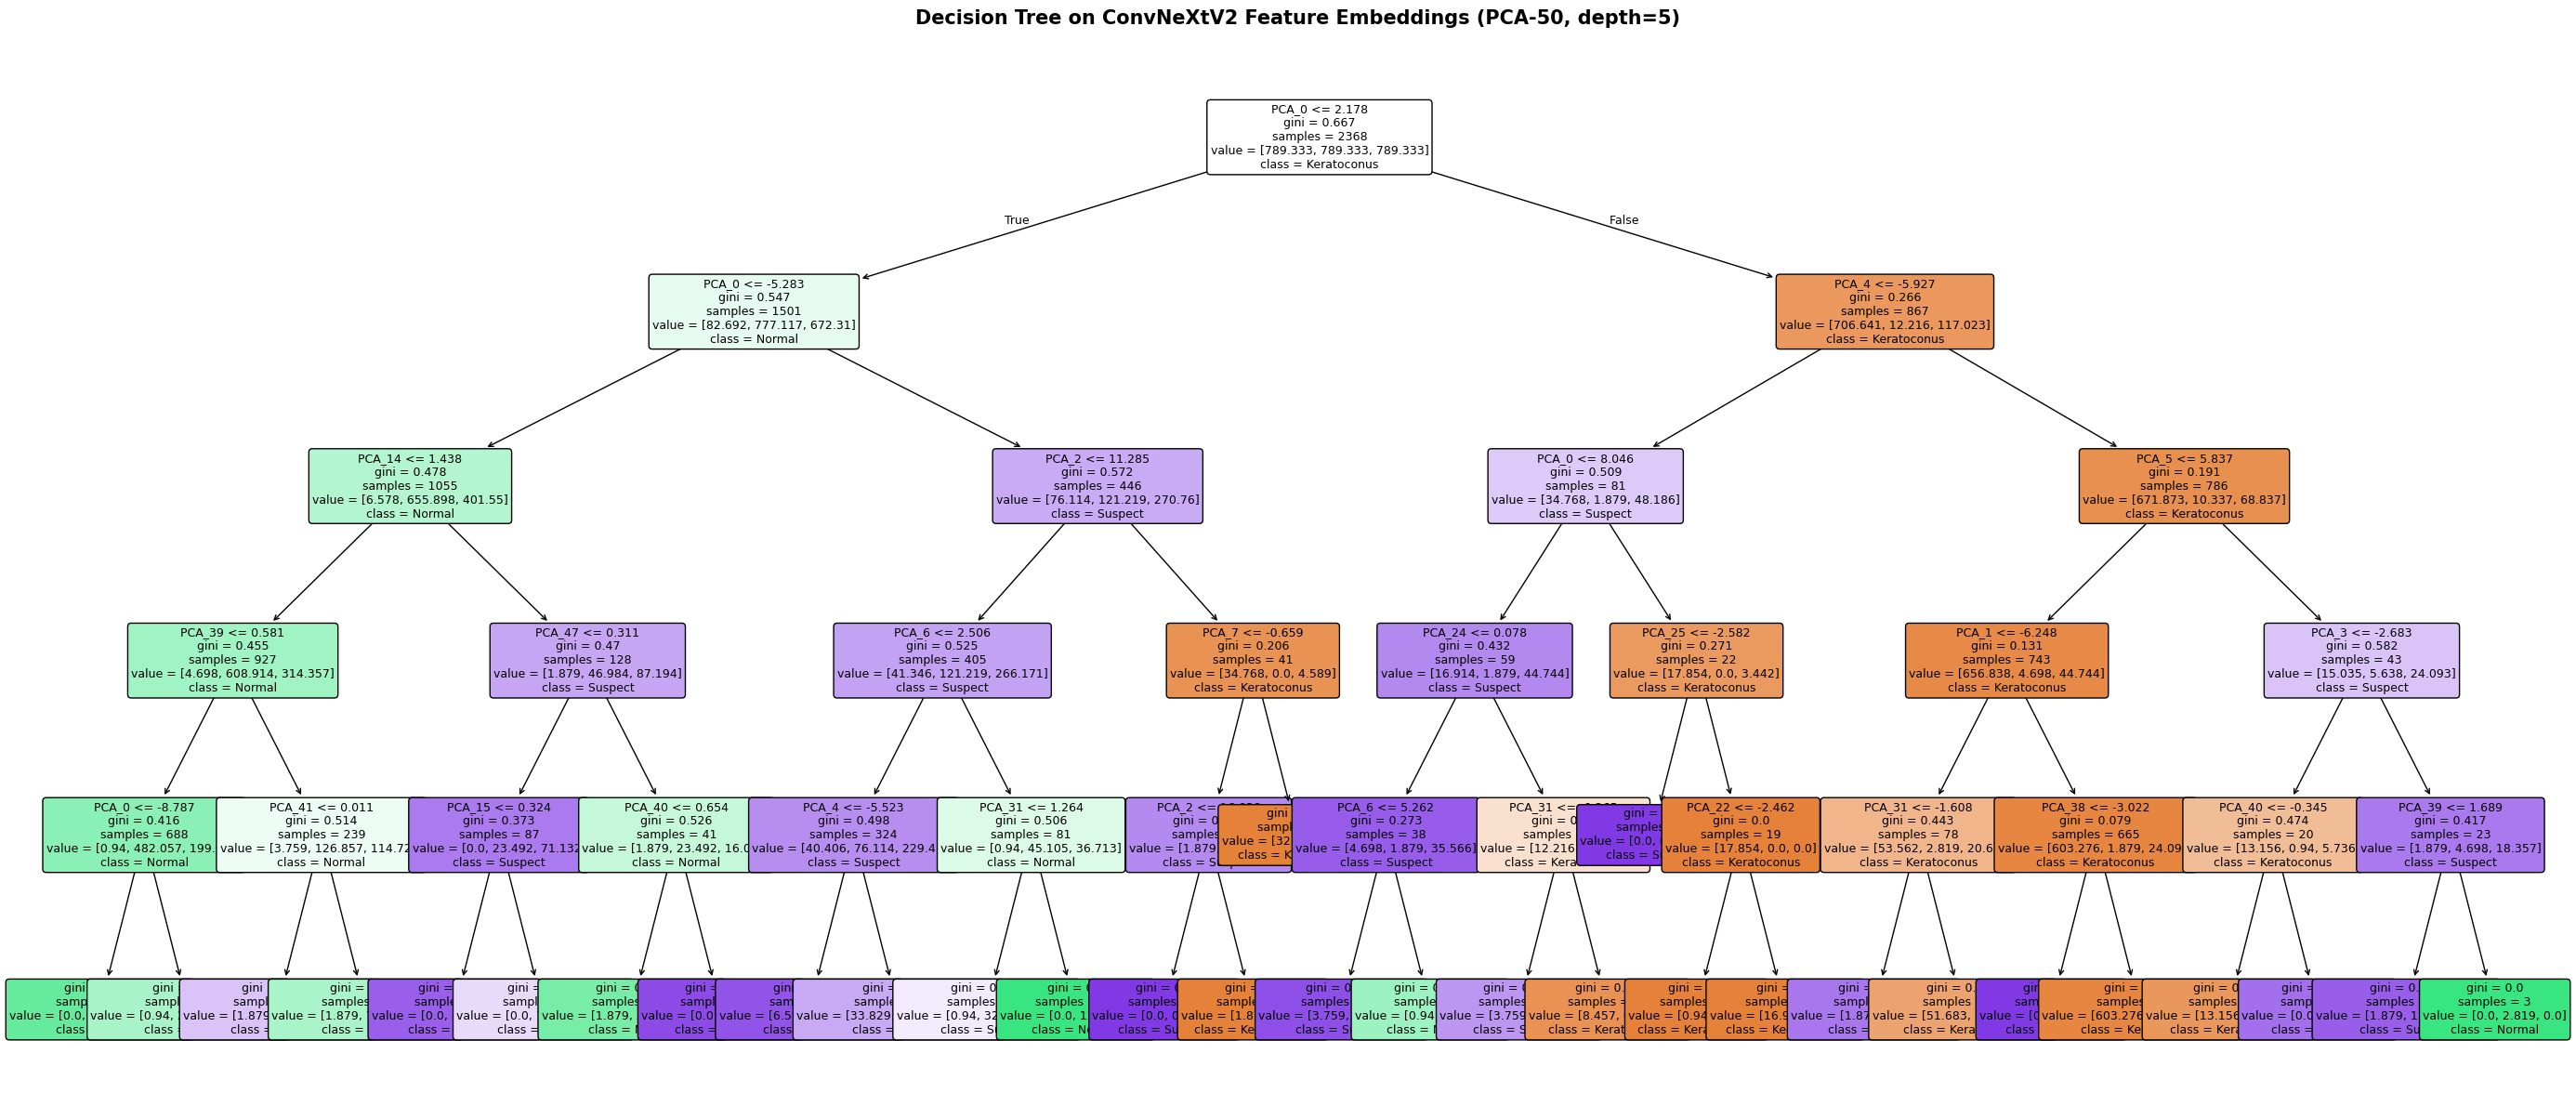

Decision tree saved.


In [19]:
# Cell 17: Visualize Decision Tree
fig, ax = plt.subplots(figsize=(28, 12))
plot_tree(
    dt,
    feature_names=[f"PCA_{i}" for i in range(50)],
    class_names=CLASS_NAMES,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
    impurity=True,
    proportion=False
)
plt.title("Decision Tree on ConvNeXtV2 Feature Embeddings (PCA-50, depth=5)",
          fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150, bbox_inches='tight')
plt.show()
print("Decision tree saved.")

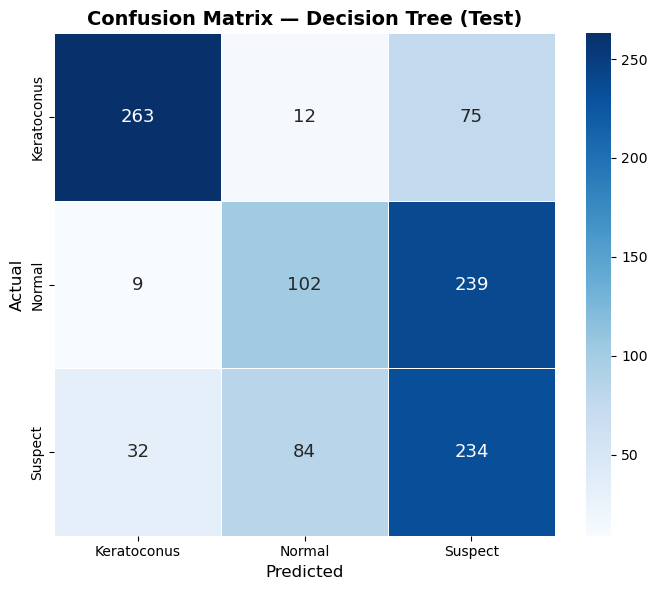

In [20]:
# Cell 18: Confusion matrix for Decision Tree
plot_confusion_matrix(y_test_feats, dt_test_preds, CLASS_NAMES,
                      title="Confusion Matrix — Decision Tree (Test)")

In [21]:
# Cell 19: AUC summary across all sets
def compute_aucs(y_true, y_probs, class_names):
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    aucs = {}
    for i, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        aucs[cls] = round(auc(fpr, tpr), 4)
    return aucs

print("\n{'='*50}")
print("AUC SUMMARY")
print(f"{'='*50}")
print(f"{'Class':<20} | {'Train AUC':>9} | {'Val AUC':>7} | {'Test AUC':>8}")
print("-" * 52)
tr_aucs = compute_aucs(tr_labels, tr_probs, CLASS_NAMES)
vl_aucs = compute_aucs(vl_labels, vl_probs, CLASS_NAMES)
te_aucs = compute_aucs(te_labels, te_probs, CLASS_NAMES)

for cls in CLASS_NAMES:
    print(f"{cls:<20} | {tr_aucs[cls]:>9} | {vl_aucs[cls]:>7} | {te_aucs[cls]:>8}")


{'='*50}
AUC SUMMARY
Class                | Train AUC | Val AUC | Test AUC
----------------------------------------------------
Keratoconus          |    0.9879 |  0.9902 |   0.9568
Normal               |     0.907 |  0.8866 |   0.7338
Suspect              |    0.8409 |   0.827 |   0.6728


In [22]:
# Cell 20: Summary of saved outputs
print("\n✅ All outputs generated:")
outputs = [
    "convnextv2_corneal.pth  — Trained model weights",
    "image_grid.png          — Sample images per class",
    "training_curves.png     — Train/Val Accuracy & Loss",
    "confusion_matrix_train.png",
    "confusion_matrix_validation.png",
    "confusion_matrix_test.png",
    "roc_curves_train.png",
    "roc_curves_validation.png",
    "roc_curves_test.png",
    "decision_tree.png       — DT on deep features (depth=5)",
    "confusion_matrix_decision_tree_(test).png",
]
for o in outputs:
    print(f"  📁 {o}")

print("\n🎉 Project complete: ConvNeXtV2 Corneal Disease Detection System")


✅ All outputs generated:
  📁 convnextv2_corneal.pth  — Trained model weights
  📁 image_grid.png          — Sample images per class
  📁 training_curves.png     — Train/Val Accuracy & Loss
  📁 confusion_matrix_train.png
  📁 confusion_matrix_validation.png
  📁 confusion_matrix_test.png
  📁 roc_curves_train.png
  📁 roc_curves_validation.png
  📁 roc_curves_test.png
  📁 decision_tree.png       — DT on deep features (depth=5)
  📁 confusion_matrix_decision_tree_(test).png

🎉 Project complete: ConvNeXtV2 Corneal Disease Detection System
